<a href="https://colab.research.google.com/github/dharanishree-p/FDS_RECORD/blob/main/03_Ex_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

         Date    Product  Sales  Quantity Region
0  2023-01-01  product A    200         4  North
1  2023-01-02  product B    150         3  South
2  2023-01-03  product A    220         5  North
3  2023-01-04  product C    300         6   East
4  2023-01-05  product B    180         4   West
Date        0
Product     0
Sales       0
Quantity    0
Region      0
dtype: int64
            Sales  Quantity
count    5.000000  5.000000
mean   210.000000  4.400000
std     56.568542  1.140175
min    150.000000  3.000000
25%    180.000000  4.000000
50%    200.000000  4.000000
75%    220.000000  5.000000
max    300.000000  6.000000
     Product  Sales  Quantity
0  product A    420         9
1  product B    330         7
2  product C    300         6


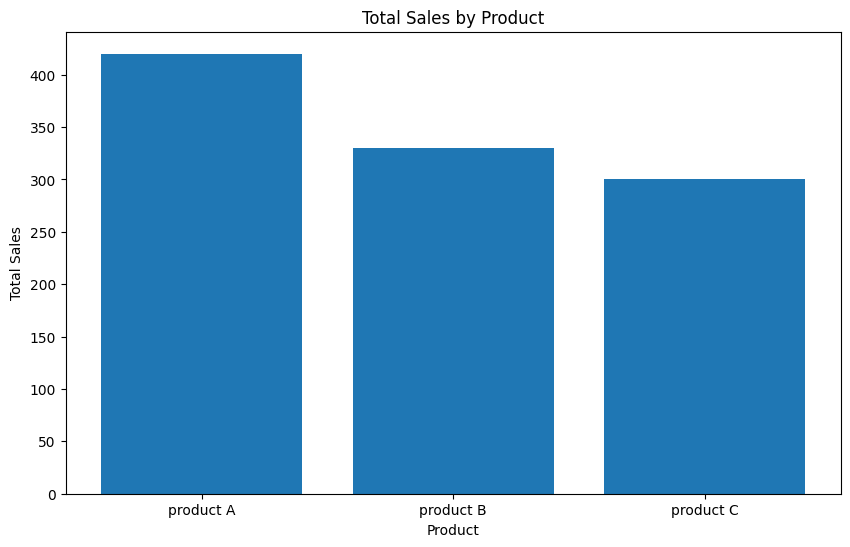

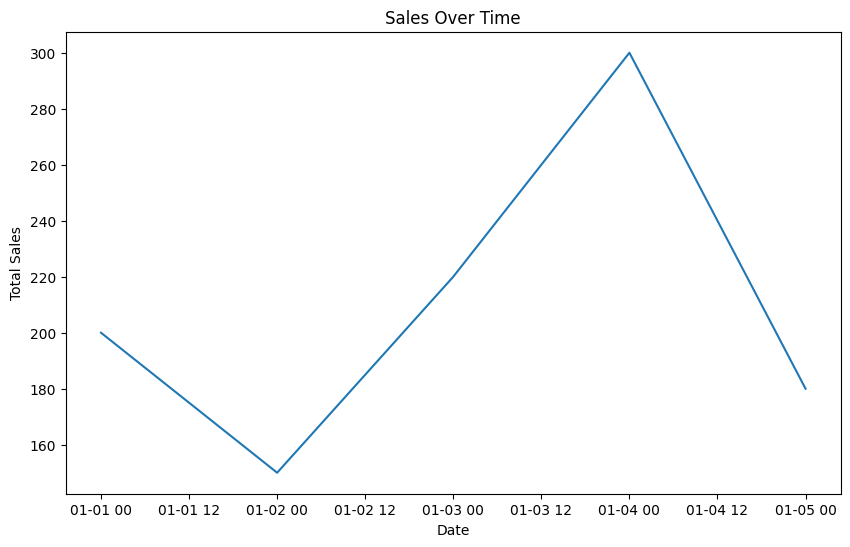

Product  product A  product B  product C
Region                                  
East             0          0        300
North          420          0          0
South            0        150          0
West             0        180          0
             Sales  Quantity
Sales     1.000000  0.969021
Quantity  0.969021  1.000000


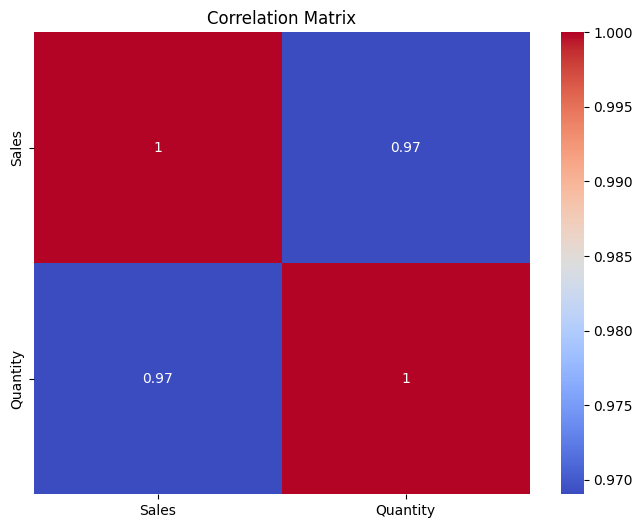

In [3]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
warnings.filterwarnings('ignore')
df = pd.read_csv("products - Sheet1.csv")
print(df.head())
print(df.isnull().sum())
df["Sales"] = df["Sales"].fillna(df["Sales"].mean())
df.dropna(subset=["Product", "Quantity", "Region"], inplace=True)
print(df.describe())
product_summary = (
    df.groupby("Product")
    .agg({"Sales": "sum", "Quantity": "sum"})
    .reset_index()
)
print(product_summary)
plt.figure(figsize=(10, 6))
plt.bar(product_summary["Product"], product_summary["Sales"])
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.title("Total Sales by Product")
plt.show()
df["Date"] = pd.to_datetime(df["Date"])
sales_over_time = df.groupby("Date").agg({"Sales": "sum"}).reset_index()
plt.figure(figsize=(10, 6))
plt.plot(sales_over_time["Date"], sales_over_time["Sales"])
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.title("Sales Over Time")
plt.show()
pivot_table = df.pivot_table(
    values="Sales",
    index="Region",
    columns="Product",
    aggfunc="sum",
    fill_value=0,
)
print(pivot_table)
correlation_matrix = df.corr(numeric_only=True)
print(correlation_matrix)
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()